# 05_kpi_ventas

**Origen:** `05_kpi_ventas.ktr` (transformación de Pentaho)  
**Fecha:** 2026-10-27  
**Biblioteca:** pandas  
**Cobertura:** Steps: 11 (11 exactos, 0 aproximados, 0 a completar)

*Generado por Pentaho Live a partir de la transformación.*

## Cómo correrlo

1. Instala las bibliotecas: `pip install pandas numpy sqlalchemy matplotlib`
2. Deja este archivo en la carpeta del .ktr (las rutas relativas parten de ahí).
3. Variables de entorno: `PDI_PASSWORD_DW_GRANO_DE_ORO` (las contraseñas nunca van en el código).

In [1]:
import pandas as pd
import numpy as np
import os
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# carpeta del script (o del notebook): la misma que la del .ktr
AQUI = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
VARS = {
    "Internal.Transformation.Filename.Directory": os.environ.get("Internal.Transformation.Filename.Directory", AQUI),
    "Internal.Entry.Current.Directory": os.environ.get("Internal.Entry.Current.Directory", AQUI),
    "Internal.Transformation.Name": "05_kpi_ventas",
}

engine_dw_grano_de_oro = create_engine("sqlite:///" + f"{VARS['Internal.Entry.Current.Directory']}/../salida/grano_de_oro_dw.sqlite")


def _redondear(serie, decimales=0, modo="HALF_EVEN"):
    """Redondea como PDI (BigDecimal de Java): modo UP, DOWN, CEILING, FLOOR, HALF_UP, HALF_DOWN, HALF_EVEN o HALF_CEILING."""
    import decimal
    serie = pd.Series(serie)
    decs = decimales if isinstance(decimales, pd.Series) else pd.Series(decimales, index=serie.index)
    modos = modo if isinstance(modo, pd.Series) else pd.Series(modo, index=serie.index)
    def uno(x, d, m):
        if pd.isna(x) or pd.isna(d):
            return np.nan
        if m == "HALF_CEILING":
            m = "HALF_UP" if x >= 0 else "HALF_DOWN"
        q = decimal.Decimal(1).scaleb(-int(d))
        return float(decimal.Decimal(repr(float(x))).quantize(q, rounding=getattr(decimal, "ROUND_" + m)))
    return pd.Series([uno(x, d, m) for x, d, m in zip(serie, decs, modos)], index=serie.index, dtype=float)


def _escribir_texto(df, ruta, sep=";", encierro='"', forzar=False, cabecera=True, anexar=False,
                    codificacion="utf-8", fin="\r\n", textos=()):
    """Escribe df como el Text file output de PDI: encierra los campos de texto (siempre si forzar;
    si no, sólo los que llevan el separador, el encierro o un salto de línea) y pone la cabecera si el
    archivo es nuevo."""
    nuevo = not (anexar and os.path.exists(ruta) and os.path.getsize(ruta) > 0)
    columnas = []
    for c in df.columns:
        s = df[c].astype(object).map(lambda v: "" if v is None or pd.isna(v) else str(v))
        if c in textos and encierro:
            if forzar:
                poner = s != ""
            else:
                poner = s.str.contains(sep, regex=False) | s.str.contains(encierro, regex=False) \
                    | s.str.contains("\n", regex=False)
            s = s.where(~poner, encierro + s.str.replace(encierro, encierro * 2, regex=False) + encierro)
        columnas.append(s)
    with open(ruta, "a" if anexar else "w", encoding=codificacion, newline="") as f:
        if cabecera and nuevo:
            f.write(sep.join(encierro + str(c) + encierro if forzar and c in textos else str(c)
                             for c in df.columns) + fin)
        if columnas:
            lineas = columnas[0]
            for s in columnas[1:]:
                lineas = lineas + sep + s
            f.write("".join(linea + fin for linea in lineas))


def _nombre_salida(nombre, extension="", fecha="", parte=None):
    """Nombre del archivo como lo arma PDI: nombre[fecha][_parte].extensión."""
    import datetime
    r = nombre + (datetime.datetime.now().strftime(fecha) if fecha else "")
    if parte is not None:
        r += f"_{parte}"
    return r + ("." + extension if extension else "")

import matplotlib.pyplot as plt

## 1. Leer modelo estrella

`TableInput`

Lee la tabla hechos_ventas (dw_grano_de_oro)

> Nota: Los tipos los decide el driver de Python/JDBC: pueden diferir un poco de los de PDI.

In [2]:
df_leer_modelo_estrella = pd.read_sql_query(text("""SELECT t.nombre AS tienda,
       p.categoria,
       h.id_ticket,
       h.cantidad,
       h.importe
FROM hechos_ventas h
JOIN dim_tienda t ON t.sk_tienda = h.sk_tienda
JOIN dim_producto p ON p.sk_producto = h.sk_producto"""), engine_dw_grano_de_oro)
df_leer_modelo_estrella.head(10)

,tienda,categoria,id_ticket,cantidad,importe
0,Malasaña,Bollería,TK000001,1,1.8
1,Malasaña,Bollería,TK000002,1,1.8
2,Malasaña,Café,TK000002,2,5.6
3,Malasaña,Bollería,TK000003,1,1.8
4,Malasaña,Café,TK000003,1,2.1
5,Malasaña,Salado,TK000004,1,3.2
6,Malasaña,Bebidas,TK000004,1,3.0
7,Malasaña,Salado,TK000005,2,6.4
8,Malasaña,Café,TK000005,1,2.1
9,Malasaña,Café,TK000006,1,3.0


## 2. Ordenar por tienda y categoría

`SortRows`

Ordena por tienda, categoria

In [3]:
df_ordenar_por_tienda_y_categoria = df_leer_modelo_estrella.sort_values(["tienda", "categoria"], ascending=True, na_position="first", kind="stable")
df_ordenar_por_tienda_y_categoria = df_ordenar_por_tienda_y_categoria.reset_index(drop=True)
df_ordenar_por_tienda_y_categoria.head(10)

,tienda,categoria,id_ticket,cantidad,importe
0,Chamberí,Bebidas,TK000019,1,4.2
1,Chamberí,Bebidas,TK000021,1,1.5
2,Chamberí,Bebidas,TK000023,1,2.9
3,Chamberí,Bebidas,TK000069,1,3.0
4,Chamberí,Bebidas,TK000071,1,2.9
5,Chamberí,Bebidas,TK000073,2,3.0
6,Chamberí,Bebidas,TK000115,2,6.0
7,Chamberí,Bebidas,TK000116,1,1.5
8,Chamberí,Bebidas,TK000120,2,6.0
9,Chamberí,Bebidas,TK000121,1,2.9


## 3. Ordenar por tienda

`SortRows`

Ordena por tienda

In [4]:
df_ordenar_por_tienda = df_leer_modelo_estrella.sort_values(["tienda"], ascending=True, na_position="first", kind="stable")
df_ordenar_por_tienda = df_ordenar_por_tienda.reset_index(drop=True)
df_ordenar_por_tienda.head(10)

,tienda,categoria,id_ticket,cantidad,importe
0,Chamberí,Bollería,TK000018,1,2.3
1,Chamberí,Café,TK000018,2,3.8
2,Chamberí,Bebidas,TK000019,1,4.2
3,Chamberí,Bollería,TK000019,1,1.8
4,Chamberí,Café,TK000019,1,1.5
5,Chamberí,Salado,TK000020,1,3.2
6,Chamberí,Café,TK000020,1,2.8
7,Chamberí,Salado,TK000020,1,2.8
8,Chamberí,Bebidas,TK000021,1,1.5
9,Chamberí,Bollería,TK000021,1,1.8


## 4. Ventas por tienda y categoría

`GroupBy`

Agrupa por tienda, categoria (2 totales)

In [5]:
# Group by de PDI agrupa filas SEGUIDAS con la misma clave (espera la entrada ordenada).
df_ventas_por_tienda_y_categoria = df_ordenar_por_tienda_y_categoria.groupby(["tienda", "categoria"], sort=False, dropna=False).agg(**{
    "unidades": ("cantidad", lambda s: s.sum(min_count=1)),
    "importe_sin_redondear": ("importe", lambda s: s.sum(min_count=1)),
}).reset_index()
df_ventas_por_tienda_y_categoria.head(10)

,tienda,categoria,unidades,importe_sin_redondear
0,Chamberí,Bebidas,91,248.7
1,Chamberí,Bollería,166,388.4
2,Chamberí,Café,359,787.1
3,Chamberí,Infusiones,75,201.7
4,Chamberí,Salado,139,463.9
5,Malasaña,Bebidas,117,317.7
6,Malasaña,Bollería,247,577.7
7,Malasaña,Café,495,1069.4
8,Malasaña,Infusiones,115,295.9
9,Malasaña,Salado,155,561.8


## 5. Totales por tienda

`GroupBy`

Agrupa por tienda (2 totales)

In [6]:
# Group by de PDI agrupa filas SEGUIDAS con la misma clave (espera la entrada ordenada).
df_totales_por_tienda = df_ordenar_por_tienda.groupby(["tienda"], sort=False, dropna=False).agg(**{
    "importe_sin_redondear": ("importe", lambda s: s.sum(min_count=1)),
    "num_tickets": ("id_ticket", "nunique"),
}).reset_index()
df_totales_por_tienda.head(10)

,tienda,importe_sin_redondear,num_tickets
0,Chamberí,2089.8,354
1,Malasaña,2822.5,460
2,Retiro,1696.1,287
3,Salamanca,2348.9,392


## 6. Redondear importe

`Calculator`

Calcula dos_decimales, importe

In [7]:
df_redondear_importe = df_ventas_por_tienda_y_categoria.copy()
df_redondear_importe["dos_decimales"] = pd.Series(2, index=df_redondear_importe.index, dtype="Int64")
df_redondear_importe["importe"] = _redondear(df_redondear_importe["importe_sin_redondear"], df_redondear_importe["dos_decimales"], "HALF_UP")
df_redondear_importe = df_redondear_importe.drop(columns=["dos_decimales"])  # campos temporales
df_redondear_importe.head(10)

,tienda,categoria,unidades,importe_sin_redondear,importe
0,Chamberí,Bebidas,91,248.7,248.7
1,Chamberí,Bollería,166,388.4,388.4
2,Chamberí,Café,359,787.1,787.1
3,Chamberí,Infusiones,75,201.7,201.7
4,Chamberí,Salado,139,463.9,463.9
5,Malasaña,Bebidas,117,317.7,317.7
6,Malasaña,Bollería,247,577.7,577.7
7,Malasaña,Café,495,1069.4,1069.4
8,Malasaña,Infusiones,115,295.9,295.9
9,Malasaña,Salado,155,561.8,561.8


## 7. Calcular ticket medio

`Calculator`

Calcula dos_decimales, importe_total, ticket_sin_redondear, ticket_medio

In [8]:
df_calcular_ticket_medio = df_totales_por_tienda.copy()
df_calcular_ticket_medio["dos_decimales"] = pd.Series(2, index=df_calcular_ticket_medio.index, dtype="Int64")
df_calcular_ticket_medio["importe_total"] = _redondear(df_calcular_ticket_medio["importe_sin_redondear"], df_calcular_ticket_medio["dos_decimales"], "HALF_UP")
df_calcular_ticket_medio["ticket_sin_redondear"] = (df_calcular_ticket_medio["importe_sin_redondear"] / df_calcular_ticket_medio["num_tickets"])
df_calcular_ticket_medio["ticket_medio"] = _redondear(df_calcular_ticket_medio["ticket_sin_redondear"], df_calcular_ticket_medio["dos_decimales"], "HALF_UP")
df_calcular_ticket_medio = df_calcular_ticket_medio.drop(columns=["dos_decimales", "ticket_sin_redondear"])  # campos temporales
df_calcular_ticket_medio.head(10)

,tienda,importe_sin_redondear,num_tickets,importe_total,ticket_medio
0,Chamberí,2089.8,354,2089.8,5.90
1,Malasaña,2822.5,460,2822.5,6.14
2,Retiro,1696.1,287,1696.1,5.91
3,Salamanca,2348.9,392,2348.9,5.99


## 8. Cargar KPI tienda y categoría

`TableOutput`

Escribe en la tabla kpi_ventas_tienda_categoria (dw_grano_de_oro)

In [9]:
df_cargar_kpi_tienda_y_categoria = df_redondear_importe
with engine_dw_grano_de_oro.begin() as _con:
    _con.execute(text("DELETE FROM kpi_ventas_tienda_categoria"))  # vaciar la tabla (truncate)
df_redondear_importe[["tienda", "categoria", "unidades", "importe"]].to_sql("kpi_ventas_tienda_categoria", engine_dw_grano_de_oro, if_exists="append", index=False, chunksize=1000)
df_cargar_kpi_tienda_y_categoria.head(10)

,tienda,categoria,unidades,importe_sin_redondear,importe
0,Chamberí,Bebidas,91,248.7,248.7
1,Chamberí,Bollería,166,388.4,388.4
2,Chamberí,Café,359,787.1,787.1
3,Chamberí,Infusiones,75,201.7,201.7
4,Chamberí,Salado,139,463.9,463.9
5,Malasaña,Bebidas,117,317.7,317.7
6,Malasaña,Bollería,247,577.7,577.7
7,Malasaña,Café,495,1069.4,1069.4
8,Malasaña,Infusiones,115,295.9,295.9
9,Malasaña,Salado,155,561.8,561.8


## 9. CSV KPI tienda y categoría

`TextFileOutput`

Escribe kpi_ventas_tienda_categoria.csv

In [10]:
df_csv_kpi_tienda_y_categoria = df_redondear_importe
sal_csv_kpi_tienda_y_categoria = df_redondear_importe[["tienda", "categoria", "unidades", "importe"]].copy()
ruta_csv_kpi_tienda_y_categoria = _nombre_salida(f"{VARS['Internal.Entry.Current.Directory']}/../salida/kpi_ventas_tienda_categoria", "csv")
_escribir_texto(sal_csv_kpi_tienda_y_categoria, ruta_csv_kpi_tienda_y_categoria, sep=";", encierro="\"", fin="\n",
                codificacion="UTF-8", textos=["tienda", "categoria", "unidades", "importe"])
df_csv_kpi_tienda_y_categoria.head(10)

,tienda,categoria,unidades,importe_sin_redondear,importe
0,Chamberí,Bebidas,91,248.7,248.7
1,Chamberí,Bollería,166,388.4,388.4
2,Chamberí,Café,359,787.1,787.1
3,Chamberí,Infusiones,75,201.7,201.7
4,Chamberí,Salado,139,463.9,463.9
5,Malasaña,Bebidas,117,317.7,317.7
6,Malasaña,Bollería,247,577.7,577.7
7,Malasaña,Café,495,1069.4,1069.4
8,Malasaña,Infusiones,115,295.9,295.9
9,Malasaña,Salado,155,561.8,561.8


## 10. Cargar KPI ticket medio

`TableOutput`

Escribe en la tabla kpi_ticket_medio_tienda (dw_grano_de_oro)

In [11]:
df_cargar_kpi_ticket_medio = df_calcular_ticket_medio
with engine_dw_grano_de_oro.begin() as _con:
    _con.execute(text("DELETE FROM kpi_ticket_medio_tienda"))  # vaciar la tabla (truncate)
df_calcular_ticket_medio[["tienda", "importe_total", "num_tickets", "ticket_medio"]].to_sql("kpi_ticket_medio_tienda", engine_dw_grano_de_oro, if_exists="append", index=False, chunksize=1000)
df_cargar_kpi_ticket_medio.head(10)

,tienda,importe_sin_redondear,num_tickets,importe_total,ticket_medio
0,Chamberí,2089.8,354,2089.8,5.90
1,Malasaña,2822.5,460,2822.5,6.14
2,Retiro,1696.1,287,1696.1,5.91
3,Salamanca,2348.9,392,2348.9,5.99


## 11. CSV KPI ticket medio

`TextFileOutput`

Escribe kpi_ticket_medio_tienda.csv

In [12]:
df_csv_kpi_ticket_medio = df_calcular_ticket_medio
sal_csv_kpi_ticket_medio = df_calcular_ticket_medio[["tienda", "importe_total", "num_tickets", "ticket_medio"]].copy()
ruta_csv_kpi_ticket_medio = _nombre_salida(f"{VARS['Internal.Entry.Current.Directory']}/../salida/kpi_ticket_medio_tienda", "csv")
_escribir_texto(sal_csv_kpi_ticket_medio, ruta_csv_kpi_ticket_medio, sep=";", encierro="\"", fin="\n",
                codificacion="UTF-8", textos=["tienda", "importe_total", "num_tickets", "ticket_medio"])
df_csv_kpi_ticket_medio.head(10)

,tienda,importe_sin_redondear,num_tickets,importe_total,ticket_medio
0,Chamberí,2089.8,354,2089.8,5.90
1,Malasaña,2822.5,460,2822.5,6.14
2,Retiro,1696.1,287,1696.1,5.91
3,Salamanca,2348.9,392,2348.9,5.99


## Análisis exploratorio

Para cada entrada y cada salida: forma, tipos, nulos, estadísticas, histogramas de las columnas numéricas y las categorías más frecuentes.

In [13]:
def eda(df, titulo, max_filas=10000):
    """Análisis exploratorio de un DataFrame: forma, tipos, nulos, estadísticas y gráficos."""
    print(f"== {titulo}: {df.shape[0]} filas x {df.shape[1]} columnas")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulos": df.isna().sum()}))
    if df.empty:
        return
    print(df.describe(include="all").T)
    numericas = df.select_dtypes(include="number").columns.tolist()
    if numericas:
        df[numericas].hist(bins=20, figsize=(4 * min(len(numericas), 3), 3 * ((len(numericas) + 2) // 3)), layout=((len(numericas) + 2) // 3, min(len(numericas), 3)))
        plt.suptitle(titulo + " - distribución de las columnas numéricas")
        plt.tight_layout()
        plt.show()
    texto = [c for c in df.columns if c not in numericas][:3]
    for c in texto:
        top = df[c].astype(str).value_counts().head(10)
        if 1 < len(top) and top.iloc[0] > 1:
            top.sort_values().plot.barh(figsize=(6, 3), title=f"{titulo} - {c} (top 10)")
            plt.tight_layout()
            plt.show()

### Entrada «Leer modelo estrella»

== Entrada «Leer modelo estrella»: 2885 filas x 5 columnas
             dtype  nulos
tienda      object      0
categoria   object      0
id_ticket   object      0
cantidad     int64      0
importe    float64      0
            count unique       top  freq      mean       std  min  25%  50%  \
tienda       2885      4  Malasaña   890       NaN       NaN  NaN  NaN  NaN   
categoria    2885      5      Café  1269       NaN       NaN  NaN  NaN  NaN   
id_ticket    2885   1493  TK001446     4       NaN       NaN  NaN  NaN  NaN   
cantidad   2885.0    NaN       NaN   NaN  1.246101  0.529068  1.0  1.0  1.0   
importe    2885.0    NaN       NaN   NaN  3.104783  1.681596  1.4  2.1  2.8   

           75%   max  
tienda     NaN   NaN  
categoria  NaN   NaN  
id_ticket  NaN   NaN  
cantidad   1.0   3.0  
importe    3.6  13.5  


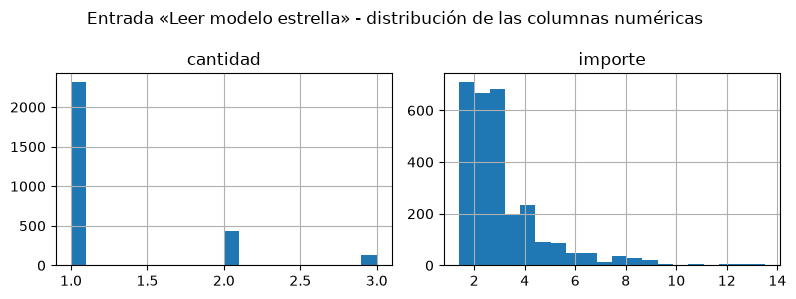

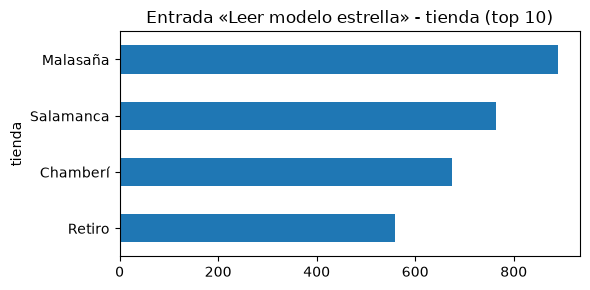

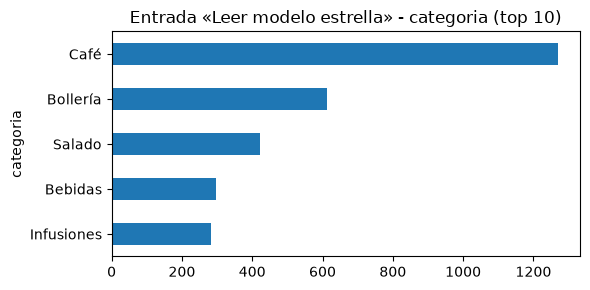

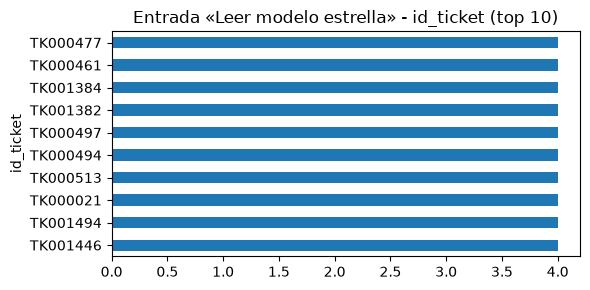

In [14]:
eda(df_leer_modelo_estrella, "Entrada «Leer modelo estrella»")

### Salida «Cargar KPI tienda y categoría»

== Salida «Cargar KPI tienda y categoría»: 20 filas x 5 columnas
                         dtype  nulos
tienda                  object      0
categoria               object      0
unidades                 int64      0
importe_sin_redondear  float64      0
importe                float64      0
                      count unique       top freq     mean         std    min  \
tienda                   20      4  Chamberí    5      NaN         NaN    NaN   
categoria                20      5   Bebidas    4      NaN         NaN    NaN   
unidades               20.0    NaN       NaN  NaN   179.75  122.827168   59.0   
importe_sin_redondear  20.0    NaN       NaN  NaN  447.865  248.302386  149.8   
importe                20.0    NaN       NaN  NaN  447.865  248.302386  149.8   

                         25%    50%      75%     max  
tienda                   NaN    NaN      NaN     NaN  
categoria                NaN    NaN      NaN     NaN  
unidades                92.5  138.5    209.5   495.0  


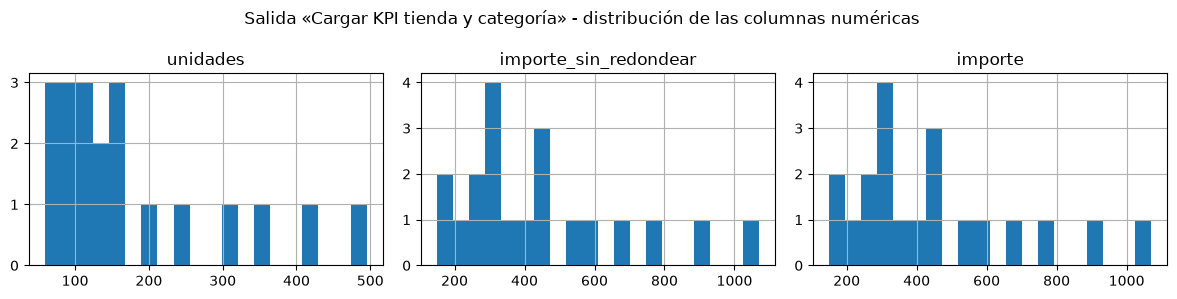

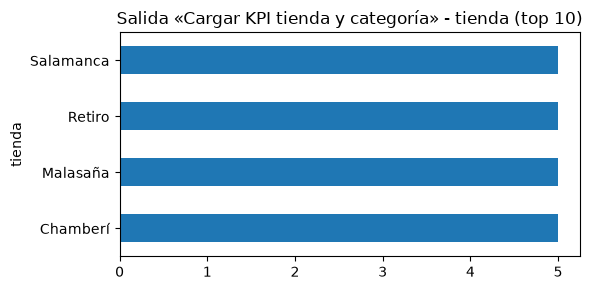

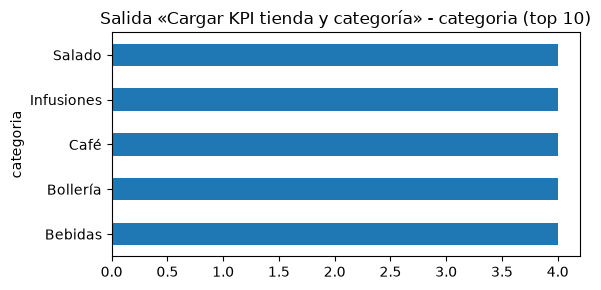

In [15]:
eda(df_cargar_kpi_tienda_y_categoria, "Salida «Cargar KPI tienda y categoría»")

### Salida «CSV KPI tienda y categoría»

== Salida «CSV KPI tienda y categoría»: 20 filas x 5 columnas
                         dtype  nulos
tienda                  object      0
categoria               object      0
unidades                 int64      0
importe_sin_redondear  float64      0
importe                float64      0
                      count unique       top freq     mean         std    min  \
tienda                   20      4  Chamberí    5      NaN         NaN    NaN   
categoria                20      5   Bebidas    4      NaN         NaN    NaN   
unidades               20.0    NaN       NaN  NaN   179.75  122.827168   59.0   
importe_sin_redondear  20.0    NaN       NaN  NaN  447.865  248.302386  149.8   
importe                20.0    NaN       NaN  NaN  447.865  248.302386  149.8   

                         25%    50%      75%     max  
tienda                   NaN    NaN      NaN     NaN  
categoria                NaN    NaN      NaN     NaN  
unidades                92.5  138.5    209.5   495.0  
imp

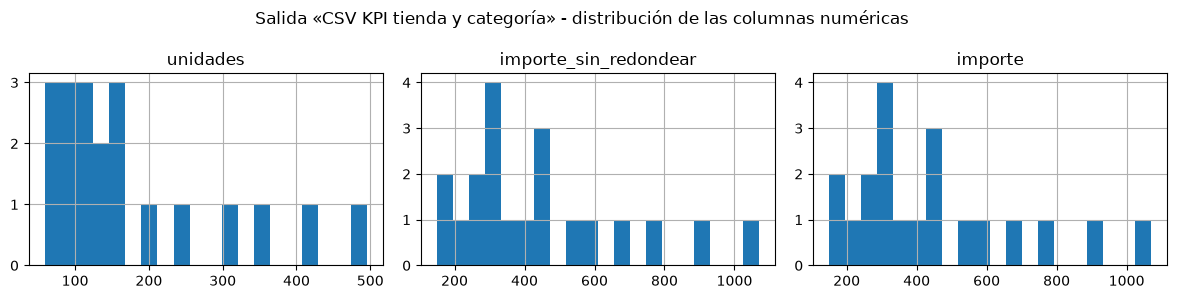

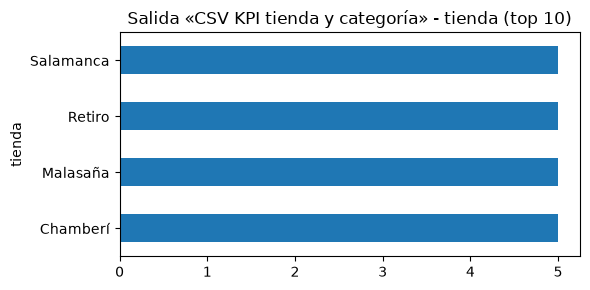

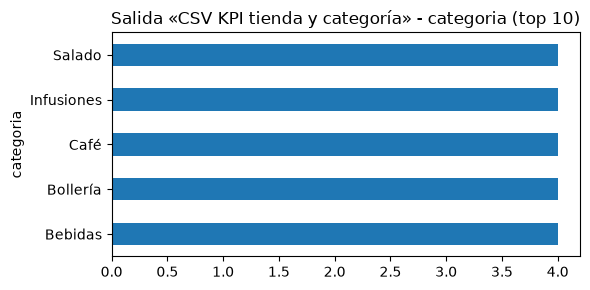

In [16]:
eda(df_csv_kpi_tienda_y_categoria, "Salida «CSV KPI tienda y categoría»")

### Salida «Cargar KPI ticket medio»

== Salida «Cargar KPI ticket medio»: 4 filas x 5 columnas
                         dtype  nulos
tienda                  object      0
importe_sin_redondear  float64      0
num_tickets              int64      0
importe_total          float64      0
ticket_medio           float64      0
                      count unique       top freq      mean         std  \
tienda                    4      4  Chamberí    1       NaN         NaN   
importe_sin_redondear   4.0    NaN       NaN  NaN  2239.325  472.423146   
num_tickets             4.0    NaN       NaN  NaN    373.25   72.311249   
importe_total           4.0    NaN       NaN  NaN  2239.325  472.423146   
ticket_medio            4.0    NaN       NaN  NaN     5.985    0.110905   

                          min       25%      50%     75%     max  
tienda                    NaN       NaN      NaN     NaN     NaN  
importe_sin_redondear  1696.1  1991.375  2219.35  2467.3  2822.5  
num_tickets             287.0    337.25    373.0   409.0   460

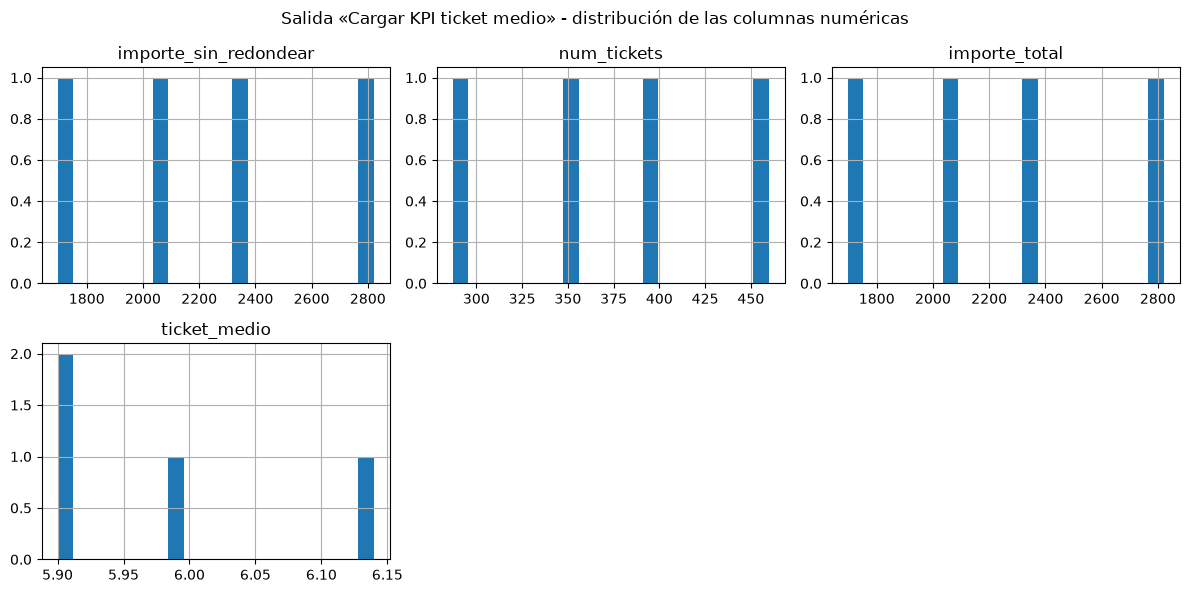

In [17]:
eda(df_cargar_kpi_ticket_medio, "Salida «Cargar KPI ticket medio»")

### Salida «CSV KPI ticket medio»

== Salida «CSV KPI ticket medio»: 4 filas x 5 columnas
                         dtype  nulos
tienda                  object      0
importe_sin_redondear  float64      0
num_tickets              int64      0
importe_total          float64      0
ticket_medio           float64      0
                      count unique       top freq      mean         std  \
tienda                    4      4  Chamberí    1       NaN         NaN   
importe_sin_redondear   4.0    NaN       NaN  NaN  2239.325  472.423146   
num_tickets             4.0    NaN       NaN  NaN    373.25   72.311249   
importe_total           4.0    NaN       NaN  NaN  2239.325  472.423146   
ticket_medio            4.0    NaN       NaN  NaN     5.985    0.110905   

                          min       25%      50%     75%     max  
tienda                    NaN       NaN      NaN     NaN     NaN  
importe_sin_redondear  1696.1  1991.375  2219.35  2467.3  2822.5  
num_tickets             287.0    337.25    373.0   409.0   460.0 

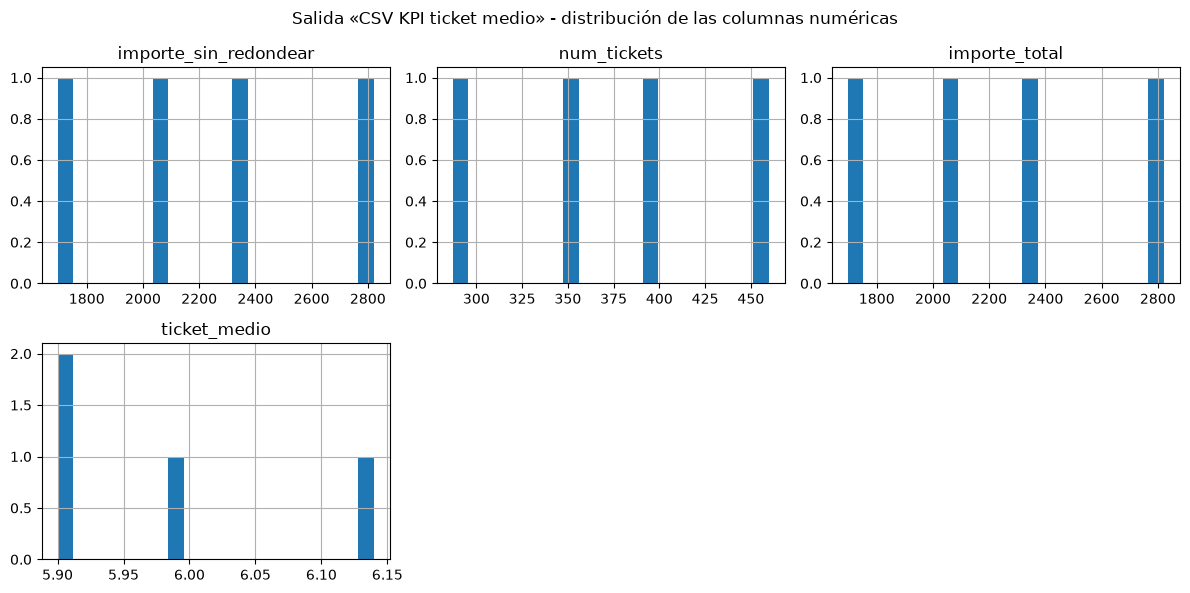

In [18]:
eda(df_csv_kpi_ticket_medio, "Salida «CSV KPI ticket medio»")

## Resumen

Steps: 11 (11 exactos, 0 aproximados, 0 a completar)

| # | Step | Tipo | Estado |
|---|---|---|---|
| 1 | Leer modelo estrella | `TableInput` | exacto |
| 2 | Ordenar por tienda y categoría | `SortRows` | exacto |
| 3 | Ordenar por tienda | `SortRows` | exacto |
| 4 | Ventas por tienda y categoría | `GroupBy` | exacto |
| 5 | Totales por tienda | `GroupBy` | exacto |
| 6 | Redondear importe | `Calculator` | exacto |
| 7 | Calcular ticket medio | `Calculator` | exacto |
| 8 | Cargar KPI tienda y categoría | `TableOutput` | exacto |
| 9 | CSV KPI tienda y categoría | `TextFileOutput` | exacto |
| 10 | Cargar KPI ticket medio | `TableOutput` | exacto |
| 11 | CSV KPI ticket medio | `TextFileOutput` | exacto |